# L'illusion flash-son : résultats

Réplication en ligne de **Shams, Kamitani & Shimojo (2000), *What you see is what you hear*, Nature 408:788** ([doi:10.1038/35048669](https://doi.org/10.1038/35048669)), avec la variante « fusion » d'**Andersen, Tiippana & Sams (2004)** ([doi:10.1016/j.cogbrainres.2004.06.004](https://doi.org/10.1016/j.cogbrainres.2004.06.004)).

**La question.** Le son peut-il changer ce que l'on *voit* ? Le participant voit 1 ou 2 flashs très brefs, accompagnés de 0, 1 ou 2 bips, et dit combien de **flashs** il a vus en ignorant les bips.

## Résumé

- **24 sessions reçues, 6 exclues** selon des critères fixés avant la collecte, **18 participants analysés** (18–25 ans) — figure 1.
- **Fission (H1, confirmée).** Avec 1 flash et 2 bips, les participants voient 2 flashs dans **54 %** des essais, contre **3 %** avec le flash seul (+51 points, p < 0,001, effet très fort : d = 1,8). 13 participants sur 18 sont trompés au moins une fois sur deux — figures 2 et 3.
- **Fusion (H2, confirmée).** Un seul bip fait « disparaître » le 2e flash : 2 flashs vus comme 1 dans **89 %** des essais contre **72 %** sans son (+17 points, p = 0,002).
- **La fission est plus forte que la fusion (H3, confirmée)** : +34 points d'écart (p < 0,001).
- **Interaction flashs × bips (H4)** : présente mais faible (p = 0,047), et due surtout au fait qu'un seul bip ne peut rien retirer quand il n'y a qu'un flash.
- **Fenêtre temporelle (H5, confirmée).** Si les 2 bips sont séparés de 200 ms au lieu de 57 ms, l'illusion disparaît presque : 12 % de « 2 flashs » au lieu de 54 % (p < 0,001).
- **Au-delà des articles** (analyses exploratoires, figures 4 à 9) :
  1. sans son, **2 vrais flashs à 50 ms d'écart ne sont vus comme 2 que dans 28 % des essais** ; avec 2 bips, dans **78 %**. Le son ne fait pas que tromper : il aide aussi à voir un vrai double flash ;
  2. en cas de conflit entre l'image et le son, la réponse suit **le son dans 71 % des cas** (17 participants sur 18) ;
  3. d'après la théorie de la détection du signal, les bips ne changent pas la capacité à distinguer 1 et 2 flashs, ils **déplacent tout vers « 2 »** ;
  4. ceux qui voient le mieux 2 flashs sans son semblent un peu **moins trompés** (corrélation −0,47, p = 0,048, à confirmer) ;
  5. les réponses illusoires sont **plus lentes** (≈ 270 ms) que les réponses à un vrai double flash : on hésite plus ;
  6. **au fil de la session**, l'aide du son pour voir 2 vrais flashs s'use (−10 points par quart de session, p = 0,006) ; la fission baisse aussi (62 % dans la 1re moitié, 45 % dans la 2e), mais cette baisse n'est pas significative (p = 0,28) ;
  7. pas de différence nette selon l'âge ou le type de son.

**En une phrase :** quand l'œil et l'oreille ne sont pas d'accord sur le nombre d'événements rapides, le cerveau fait surtout confiance à l'oreille, mais seulement si les sons tombent dans une courte fenêtre de temps autour du flash.

## Le plan de l'expérience

58 essais principaux par personne, dans un ordre aléatoire (≈ 4 min), après un test d'écoute (3 essais) et un entraînement (3 essais) :

| Partie | Conditions (F = flash, B = bip) | Essais |
|---|---|---|
| Cœur 2 × 3 | 1 ou 2 flashs × 0, 1 ou 2 bips (bips à 57 ms d'écart, flashs à 50 ms) | 6 × 8 = 48 |
| Écart | 1 flash + 2 bips séparés de **200 ms** (`1F2B_gap200`) | 6 |
| Contrôle d'attention | 2 flashs bien séparés (150 ms), sans son (`2F0B_catch`) | 4 |

**Hypothèses fixées avant la collecte** (voir [docs/PLAN.md](../docs/PLAN.md)) : **H1** fission (1F2B vu « 2 » plus souvent que 1F0B) ; **H2** fusion (2F1B vu « 1 » plus souvent que 2F0B) ; **H3** fission plus forte que fusion ; **H4** interaction flashs × bips ; **H5** moins de fission quand les bips sont séparés de 200 ms.

**Méthode statistique** (simple et robuste) : on calcule d'abord un pourcentage **par participant**, puis on compare les conditions chez les mêmes personnes avec un **t de Student apparié** (unilatéral pour H1, H2, H3 et H5, car la direction était prédite), vérifié par un **test de Wilcoxon** (qui ne suppose pas de loi normale). On donne aussi la taille d'effet (**d de Cohen**) et un **intervalle de confiance à 95 % par bootstrap**. H4 est testée par une ANOVA à mesures répétées 2 × 3.

**Comment lire les figures.** Un trait ou un point **gris** = un participant. Le point **coloré** = la moyenne du groupe. Les **barres** = intervalle de confiance à 95 % obtenu par bootstrap (on tire au hasard, 10 000 fois, un groupe de participants parmi les nôtres). Les pourcentages sont des « % de réponses » ; les tailles d'illusion sont en « points de % ».

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# --- style commun à toutes les figures ---
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"1F": "#3B75AF", "2F": "#EF8636", "illusion": "#C03D3E", "neutre": "#7F7F7F",
       "son": "#5A9E4B", "exclu": "#BBBBBB"}
INDIV = dict(color="0.55", alpha=0.35, lw=1)          # lignes individuelles

# chemins relatifs : le notebook marche depuis la racine du dépôt ou depuis analysis/
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
DATA = ROOT / "data" / "processed" / "trials_anon.csv"
FIG_DIR = ROOT / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for old in FIG_DIR.glob("*.png"):                      # on régénère toutes les figures
    old.unlink()

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

In [2]:
def boot_ci(x, n=10000):
    """IC à 95 % de la moyenne par bootstrap (on rééchantillonne les participants)."""
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    rng = np.random.default_rng(2026)   # graine fixe : résultat reproductible
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

def mean_ci(x):
    x = np.asarray(x, float)
    lo, hi = boot_ci(x)
    m = np.nanmean(x)
    return m, m - lo, hi - m            # moyenne et demi-barres (pour errorbar)

def compare(a, b, label, alternative="greater"):
    """a vs b, mêmes participants : t apparié, Wilcoxon, d de Cohen (dz) et IC bootstrap de la différence."""
    diff = (np.asarray(a, float) - np.asarray(b, float))
    t = stats.ttest_rel(a, b, alternative=alternative)
    try:
        w = stats.wilcoxon(a, b, alternative=alternative).pvalue
    except ValueError:
        w = np.nan
    lo, hi = boot_ci(diff)
    return pd.Series({"différence moyenne": diff.mean(), "IC95 bas": lo, "IC95 haut": hi,
                      "t": t.statistic, "ddl": len(diff) - 1, "p (t)": t.pvalue,
                      "p (Wilcoxon)": w, "d de Cohen (dz)": diff.mean() / diff.std(ddof=1)}, name=label)

def fmt(tab):
    out = tab.copy()
    for c in out.columns:
        if c.startswith("p "):
            out[c] = out[c].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
        elif c == "ddl":
            out[c] = out[c].astype(int)
        else:
            out[c] = out[c].astype(float).round(2)
    return out

def slope_panel(ax, a, b, labels, color, title, ylabel, pct=True):
    """Un trait par participant (avant -> après) + moyenne et IC 95 % bootstrap."""
    k = 100 if pct else 1
    for x0, x1 in zip(a * k, b * k):
        ax.plot([0, 1], [x0, x1], **INDIV)
    ax.scatter(np.zeros(len(a)), a * k, color="0.4", s=14, zorder=3)
    ax.scatter(np.ones(len(b)), b * k, color="0.4", s=14, zorder=3)
    for x, v in [(0, a), (1, b)]:
        m, lo, hi = mean_ci(v * k)
        ax.errorbar(x, m, yerr=[[lo], [hi]], fmt="o", color=color, ms=10, capsize=6, lw=2.5, zorder=4)
    ax.plot([0, 1], [np.mean(a) * k, np.mean(b) * k], color=color, lw=3, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(labels); ax.set_xlim(-0.35, 1.35)
    ax.set_title(title); ax.set_ylabel(ylabel)

## 1. Les données et les participants

Chaque session envoie automatiquement un fichier CSV (une ligne par essai). Les fichiers bruts restent privés (`data/raw/`, ignoré par git). Le script `scripts/anonymize_data.py` en tire **`data/processed/trials_anon.csv`**, publié dans le dépôt : sans code de session, ni date et heure, ni navigateur détaillé, ni taille d'écran ; les participants sont renommés P01 à P24 dans un ordre qui ne suit pas l'ordre de passage. Le fichier de test du développeur (données simulées) n'en fait pas partie.

In [3]:
df = pd.read_csv(DATA)
print(f"{df.participant.nunique()} sessions reçues, {len(df)} lignes (une ligne = un essai)")

24 sessions reçues, 1545 lignes (une ligne = un essai)


### Qui est gardé ? (critères d'exclusion)

Les critères ont été fixés **avant** de regarder les résultats ([docs/DONNEES.md](../docs/DONNEES.md)).

- **Essai retiré** : image perdue pendant le stimulus, flash en retard de plus d'une demi-image, son programmé trop tard, onglet masqué, ou réponse en moins de 100 ms (touche pressée trop tôt) ou en plus de 10 s.
- **Session exclue** : écouteurs Bluetooth (son retardé), test d'écoute raté (< 2/3), contrôles ratés (< 75 % de « 2 » pour 2 flashs bien séparés, < 70 % de « 1 » pour 1 flash seul), écran < 50 Hz (le flash et l'écart de 50 ms ne peuvent pas être affichés correctement), plus de 20 % d'essais au timing raté, moins de 80 % des essais faits.

In [4]:
def last_score(s):
    """'3/3' ou '1/3;2/3' (test d'écoute refait) -> proportion correcte à la dernière tentative."""
    a, b = str(s).split(";")[-1].split("/")
    return int(a) / int(b)

main = df[df.block == "main"].copy()
main["two"] = (main.response == 2).astype(int)      # 1 si la personne a répondu « 2 flashs »

# Critères d'essai (fixés avant la collecte, docs/DONNEES.md)
main["bad_timing"] = ((main.n_dropped_frames.fillna(0) > 0)
                      | (main.flash_late_ms.abs() > main.frame_ms / 2).fillna(False)
                      | (main.audio_scheduled_late.fillna(0) == 1)
                      | (main.tab_hidden.fillna(0) == 1))
main["bad_rt"] = (main.rt_ms < 100) | (main.rt_ms > 10000)
main["exclude_trial"] = main.bad_timing | main.bad_rt

g = main.groupby("participant")
q = pd.DataFrame({
    "age": g.age_bracket.first(), "son": g.audio_device.first(), "navigateur": g.browser.first(),
    "ecran_hz": g.refresh_hz.median().round(1),
    "test_ecoute": g.audio_check_score.first().map(last_score).round(2),
    "controle_2flashs": main[main.condition == "2F0B_catch"].groupby("participant").two.mean(),
    "controle_1flash": 1 - main[main.condition == "1F0B"].groupby("participant").two.mean(),
    "essais_timing_rate": g.bad_timing.mean().round(2),
    "n_essais": g.size(),
})
n_expected = (pd.read_csv(ROOT / "experiment" / "trials.csv").block == "main").sum()

raisons = pd.DataFrame({
    "Bluetooth": q.son == "bluetooth",
    "test d'écoute < 2/3": q.test_ecoute < 2 / 3 - 1e-9,
    "contrôle 2 flashs < 75 %": q.controle_2flashs < 0.75,
    "contrôle 1 flash < 70 %": q.controle_1flash < 0.70,
    "écran < 50 Hz": q.ecran_hz < 50,
    "timing raté > 20 % des essais": q.essais_timing_rate > 0.20,
    "incomplet": q.n_essais < 0.8 * n_expected,
})
q["exclu"] = raisons.any(axis=1)
q["raison"] = raisons.apply(lambda r: " ; ".join(r.index[r]), axis=1)
display(q)

kept = q.index[~q.exclu]
N_RECUS, N_EXCLUS, N = len(q), int(q.exclu.sum()), len(kept)
print(f"Sessions reçues : {N_RECUS} | exclues : {N_EXCLUS} | ANALYSÉES : N = {N}")
d = main[main.participant.isin(kept) & ~main.exclude_trial].copy()
print(f"Essais retirés chez les {N} participants gardés : "
      f"{main[main.participant.isin(kept)].exclude_trial.mean():.1%}")

,age,son,navigateur,ecran_hz,test_ecoute,controle_2flashs,controle_1flash,essais_timing_rate,n_essais,exclu,raison
participant,,,,,,,,,,,
P01,22-25,speakers,Edge,59.9,1.00,0.75,1.000,0.00,58,False,
P02,18-21,speakers,Chrome,60.2,1.00,1.00,1.000,0.02,58,False,
P03,18-21,speakers,Chrome,48.1,0.33,0.75,0.875,0.00,58,True,test d'écoute < 2/3 ; écran < 50 Hz
P04,18-21,speakers,Chrome,59.9,1.00,1.00,1.000,0.00,58,False,
P05,22-25,wired,Firefox,60.0,1.00,1.00,1.000,0.00,58,False,
P06,18-21,speakers,Safari,58.8,1.00,1.00,1.000,0.00,58,False,
P07,22-25,speakers,Chrome,59.9,1.00,1.00,0.875,0.02,58,False,
P08,18-21,speakers,Firefox,60.0,1.00,1.00,0.875,0.02,58,False,
P09,22-25,bluetooth,Safari,30.3,1.00,1.00,1.000,0.00,58,True,Bluetooth ; écran < 50 Hz


Sessions reçues : 24 | exclues : 6 | ANALYSÉES : N = 18
Essais retirés chez les 18 participants gardés : 2.7%


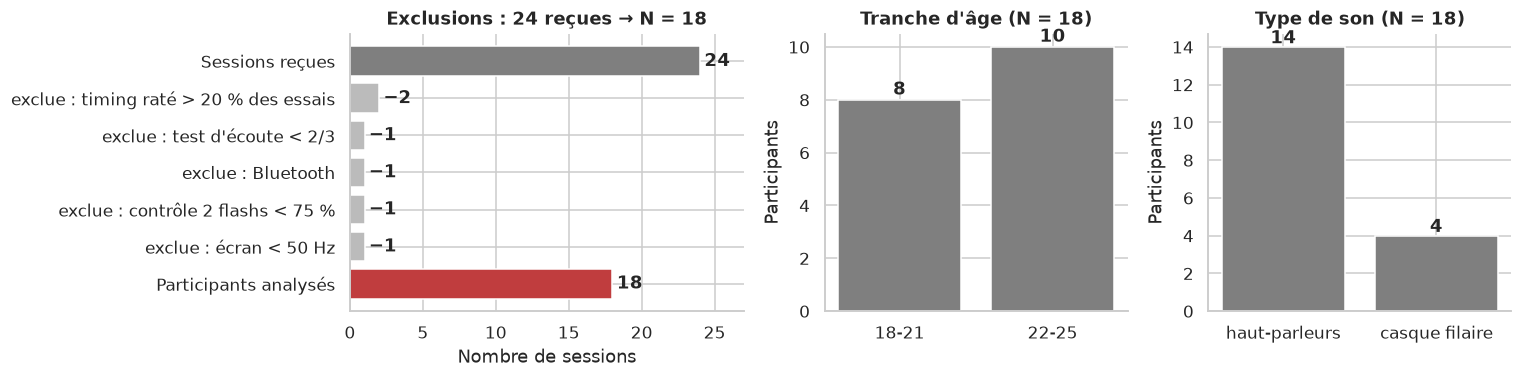

Navigateurs : {'Firefox': 8, 'Chrome': 6, 'Edge': 3, 'Safari': 1}


In [5]:
# Figure 1 : d'où viennent les N = 18 ?  (raison principale = la première de la liste qui s'applique)
principale = raisons.idxmax(axis=1).where(q.exclu, "")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
counts = principale[q.exclu].value_counts()
bars = [("Sessions reçues", N_RECUS, COL["neutre"])] + \
       [(f"exclue : {r}", -n, COL["exclu"]) for r, n in counts.items()] + \
       [("Participants analysés", N, COL["illusion"])]
for i, (lab, n, c) in enumerate(bars[::-1]):
    ax.barh(i, abs(n), color=c)
    ax.text(abs(n) + 0.3, i, f"{'−' if n < 0 else ''}{abs(n)}", va="center", fontweight="bold")
ax.set_yticks(range(len(bars))); ax.set_yticklabels([b[0] for b in bars[::-1]])
ax.set_xlabel("Nombre de sessions"); ax.set_xlim(0, N_RECUS + 3)
ax.set_title(f"Exclusions : {N_RECUS} reçues → N = {N}")
for ax, col, titre in [(axes[1], "age", "Tranche d'âge"), (axes[2], "son", "Type de son")]:
    vc = q.loc[kept, col].value_counts().sort_index()
    lab = {"speakers": "haut-parleurs", "wired": "casque filaire"}
    ax.bar([lab.get(i, i) for i in vc.index], vc.values, color=COL["neutre"])
    for i, v in enumerate(vc.values):
        ax.text(i, v + 0.2, str(v), ha="center", fontweight="bold")
    ax.set_title(f"{titre} (N = {N})"); ax.set_ylabel("Participants")
plt.tight_layout(); save(fig, "fig01_participants")
print("Navigateurs :", q.loc[kept].navigateur.value_counts().to_dict())

> **Figure 1. À retenir :** sur 24 sessions, 6 ont été écartées, surtout pour des raisons techniques (écran trop lent, images perdues). Il reste **N = 18 participants**, tous de 18 à 25 ans, en majorité sur haut-parleurs. Une session peut cumuler plusieurs raisons ; la figure montre la première : au total, 3 écrans < 50 Hz (dont une session aussi en Bluetooth et une aussi au test d'écoute raté), 2 sessions avec trop d'images perdues et 1 contrôle d'attention raté. Chez les 18 participants gardés, seuls 2,7 % des essais sont retirés.

## 2. Ce que les participants ont vu

Pour chaque participant et chaque condition, on calcule le **nombre moyen de flashs rapportés** (comme la figure 1 de Shams et al., 2000), puis la moyenne du groupe.

In [6]:
ORDER = ["1F0B", "1F1B", "1F2B", "2F0B", "2F1B", "2F2B"]
core = d[d.part == "core"]
# proportion de réponses « 2 flashs » par participant et par condition
P = d.pivot_table(index="participant", columns="condition", values="two", aggfunc="mean")
nflash = core.pivot_table(index="participant", columns="condition", values="response", aggfunc="mean")[ORDER]
print("Nombre moyen de flashs perçus (moyenne des participants ± écart-type) :")
display(nflash.agg(["mean", "std"]).round(2))
print("Pourcentage de réponses « 2 flashs » :")
display((100 * P[ORDER + ["1F2B_gap200", "2F0B_catch"]].agg(["mean", "std"])).round(0))

Nombre moyen de flashs perçus (moyenne des participants ± écart-type) :


condition,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B
mean,1.03,1.03,1.54,1.28,1.11,1.78
std,0.09,0.07,0.29,0.30,0.21,0.23


Pourcentage de réponses « 2 flashs » :


condition,1F0B,1F1B,1F2B,2F0B,2F1B,2F2B,1F2B_gap200,2F0B_catch
mean,3.0,3.0,54.0,28.0,11.0,78.0,12.0,99.0
std,9.0,7.0,29.0,30.0,21.0,23.0,29.0,6.0


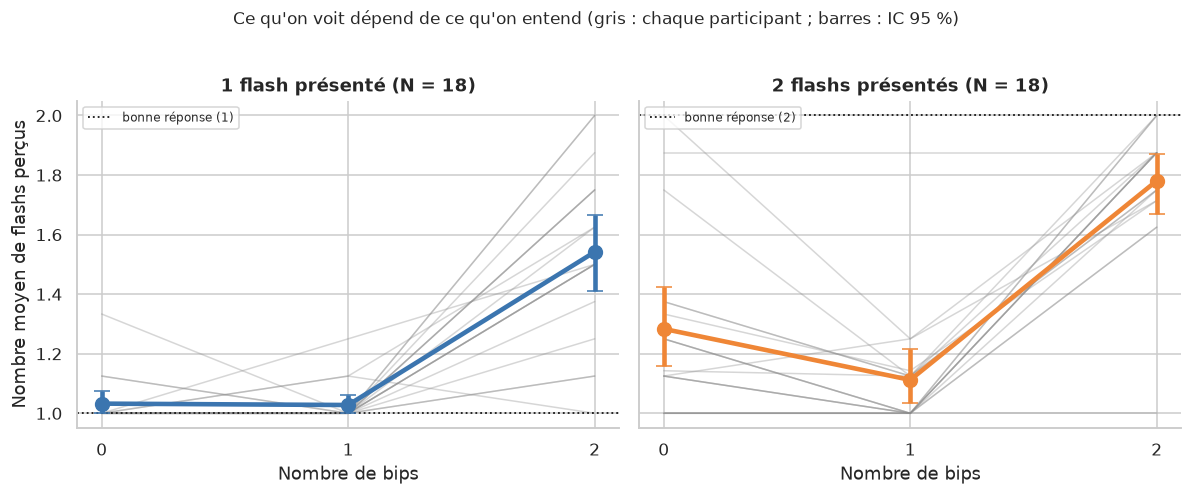

In [7]:
# Figure 2 : la figure classique de Shams et al. (2000), un panneau par nombre de flashs
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, nf in zip(axes, [1, 2]):
    cols = [f"{nf}F{b}B" for b in range(3)]
    for _, row in nflash[cols].iterrows():
        ax.plot(range(3), row.values, **INDIV)
    stat = [mean_ci(nflash[c]) for c in cols]
    ax.errorbar(range(3), [s[0] for s in stat], yerr=[[s[1] for s in stat], [s[2] for s in stat]],
                fmt="o-", color=COL[f"{nf}F"], ms=9, lw=3, capsize=5, zorder=4)
    ax.axhline(nf, color="k", ls=":", lw=1.2, label=f"bonne réponse ({nf})")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_xticks(range(3)); ax.set_xlabel("Nombre de bips")
    ax.set_title(f"{nf} flash{'s' if nf == 2 else ''} présenté{'s' if nf == 2 else ''} (N = {N})")
axes[0].set_ylabel("Nombre moyen de flashs perçus"); axes[0].set_ylim(0.95, 2.05)
fig.suptitle("Ce qu'on voit dépend de ce qu'on entend (gris : chaque participant ; barres : IC 95 %)",
             y=1.02, fontsize=11)
plt.tight_layout(); save(fig, "fig02_flashs_percus")

> **Figure 2. À retenir :** les bips tirent la réponse vers leur propre nombre. Avec 1 flash, ajouter 2 bips fait passer de 1,03 à **1,54** flash perçu en moyenne. Avec 2 flashs, 1 bip fait baisser à 1,11 et 2 bips font monter à 1,78. Le contrôle à 150 ms est réussi à 99 %, donc les participants étaient attentifs. Point inattendu : **2 flashs à 50 ms d'écart sans son ne sont vus comme 2 que dans 28 % des essais** (1,28 flash en moyenne) : sur un écran d'ordinateur ordinaire, deux flashs aussi rapprochés se confondent souvent.

## 3. Les hypothèses

### 3.1 H1, H2, H3 et H5 : tests appariés

Indices par participant : **fission** = % de « 2 » pour 1F2B − % de « 2 » pour 1F0B ; **fusion** = % de « 1 » pour 2F1B − % de « 1 » pour 2F0B. Dans le tableau, les différences sont des proportions : 0,51 = 51 points de pourcentage.

In [8]:
idx = pd.DataFrame({
    "fission": P["1F2B"] - P["1F0B"],            # « 2 » de plus quand 2 bips accompagnent 1 flash
    "fusion": (1 - P["2F1B"]) - (1 - P["2F0B"]), # « 1 » de plus quand 1 bip accompagne 2 flashs
    "fission_200ms": P["1F2B_gap200"] - P["1F0B"],
})
res = pd.DataFrame([
    compare(P["1F2B"], P["1F0B"], "H1 fission : 1F2B vs 1F0B (% « 2 »)"),
    compare(1 - P["2F1B"], 1 - P["2F0B"], "H2 fusion : 2F1B vs 2F0B (% « 1 »)"),
    compare(idx.fission, idx.fusion, "H3 fission > fusion (indices)"),
    compare(P["1F2B"], P["1F2B_gap200"], "H5 bips à 57 ms vs 200 ms (% « 2 »)"),
])
display(fmt(res))

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
H1 fission : 1F2B vs 1F0B (% « 2 »),0.51,0.38,0.63,7.67,17,"< 0,001","< 0,001",1.81
H2 fusion : 2F1B vs 2F0B (% « 1 »),0.17,0.08,0.28,3.28,17,0.002,0.002,0.77
H3 fission > fusion (indices),0.34,0.17,0.51,3.82,17,"< 0,001",0.002,0.90
H5 bips à 57 ms vs 200 ms (% « 2 »),0.42,0.27,0.57,5.35,17,"< 0,001","< 0,001",1.26


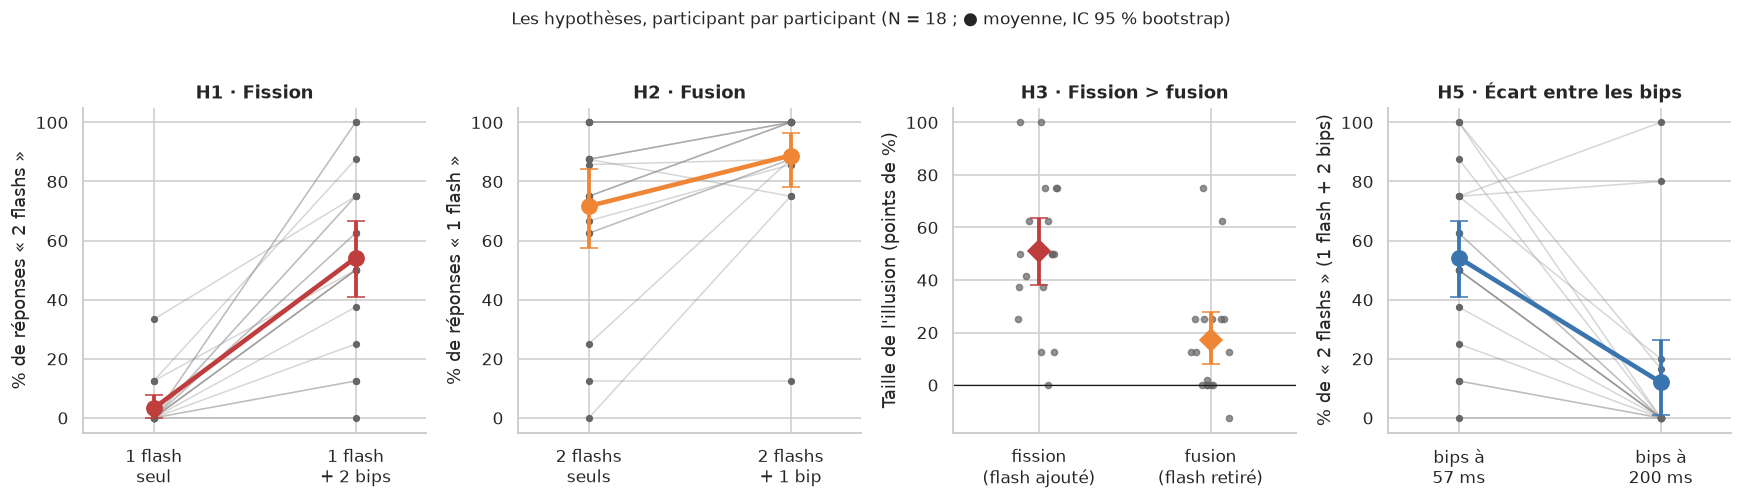

In [9]:
# Figure 3 : chaque hypothèse, chaque participant (avant -> après)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
slope_panel(axes[0], P["1F0B"], P["1F2B"], ["1 flash\nseul", "1 flash\n+ 2 bips"], COL["illusion"],
            "H1 · Fission", "% de réponses « 2 flashs »")
slope_panel(axes[1], 1 - P["2F0B"], 1 - P["2F1B"], ["2 flashs\nseuls", "2 flashs\n+ 1 bip"], COL["2F"],
            "H2 · Fusion", "% de réponses « 1 flash »")
slope_panel(axes[3], P["1F2B"], P["1F2B_gap200"], ["bips à\n57 ms", "bips à\n200 ms"], COL["1F"],
            "H5 · Écart entre les bips", "% de « 2 flashs » (1 flash + 2 bips)")
ax = axes[2]
for i, c in enumerate(["fission", "fusion"]):
    x = i + np.random.default_rng(i).uniform(-0.12, 0.12, N)
    ax.scatter(x, idx[c] * 100, color="0.4", s=16, alpha=0.7)
    m, lo, hi = mean_ci(idx[c] * 100)
    ax.errorbar(i, m, yerr=[[lo], [hi]], fmt="D", color=COL["illusion"] if i == 0 else COL["2F"],
                ms=10, capsize=6, lw=2.5, zorder=4)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks([0, 1]); ax.set_xticklabels(["fission\n(flash ajouté)", "fusion\n(flash retiré)"])
ax.set_xlim(-0.5, 1.5); ax.set_ylabel("Taille de l'illusion (points de %)"); ax.set_title("H3 · Fission > fusion")
for ax in (axes[0], axes[1], axes[3]):
    ax.set_ylim(-5, 105)
fig.suptitle(f"Les hypothèses, participant par participant (N = {N} ; ● moyenne, IC 95 % bootstrap)",
             y=1.03, fontsize=11)
plt.tight_layout(); save(fig, "fig03_hypotheses")

> **Figure 3. À retenir :** chez presque tout le monde, les traits montent pour la fission (H1) et la fusion (H2), et descendent quand les bips sont espacés de 200 ms (H5). La fission est nettement plus grande que la fusion (H3).

- **H1 (fission) confirmée** : +51 points (IC 95 % : 38 à 63), t(17) = 7,67, p < 0,001, d = 1,81.
- **H2 (fusion) confirmée** : +17 points (IC 95 % : 8 à 28), t(17) = 3,28, p = 0,002, d = 0,77. Shams et al. (2000) ne trouvaient pas de fusion nette ; nous la trouvons, comme Andersen et al. (2004), mais plus faible que la fission.
- **H3 (fission > fusion) confirmée** : écart de 34 points (IC 95 % : 17 à 51), t(17) = 3,82, p < 0,001, d = 0,90.
- **H5 (fenêtre temporelle) confirmée** : avec des bips à 200 ms d'écart, la fission tombe de 54 % à 12 % de « 2 » (−42 points, IC 95 % : 27 à 57, t(17) = 5,35, p < 0,001, d = 1,26). Le cerveau ne lie le son au flash que s'ils sont très proches dans le temps.

Le test de Wilcoxon donne les mêmes conclusions à chaque fois.

### 3.2 H4 : interaction flashs × bips (ANOVA à mesures répétées)

Variable : % de réponses « 2 » ; facteurs : nombre de flashs (1, 2) et nombre de bips (0, 1, 2). La colonne `p_GG_corr` corrige la violation de sphéricité (Greenhouse-Geisser).

In [10]:
aov = pg.rm_anova(data=core.groupby(["participant", "n_flashes", "n_beeps"], as_index=False).two.mean(),
                  dv="two", within=["n_flashes", "n_beeps"], subject="participant", correction=True)
display(aov.round(4))
gain = pd.DataFrame({f"{nf} flash(s)": (P[f"{nf}F2B"] - P[f"{nf}F0B"]) for nf in (1, 2)})
print("Hausse des « 2 » avec 2 bips (vs 0 bip), en points :", (100 * gain.mean()).round(0).to_dict())

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps,sphericity,W_spher,p_spher
0,n_flashes,0.9898,1,17,0.9898,12.7296,0.0024,0.0024,0.1707,1.0000,True,NaN,1.0000
1,n_beeps,7.3279,2,34,3.6639,70.9384,0.0000,0.0000,0.6037,0.6362,False,0.4282,0.0011
2,n_flashes * n_beeps,0.1556,2,34,0.0778,3.4366,0.0437,0.0470,0.0313,0.9429,True,0.9395,0.6068


Hausse des « 2 » avec 2 bips (vs 0 bip), en points : {'1 flash(s)': 51.0, '2 flash(s)': 50.0}


**Résultats.** Le nombre de **bips** a un effet énorme (F(2, 34) = 70,9, p < 0,001, η²g = 0,60), bien plus grand que celui du nombre réel de **flashs** (F(1, 17) = 12,7, p = 0,002, η²g = 0,17). **H4** : l'interaction est significative mais faible (F(2, 34) = 3,44, p = 0,047 après correction, η²g = 0,03). On la voit sur la figure 2 : le bip unique fait baisser les « 2 » quand il y a 2 flashs (fusion), mais ne peut rien faire quand il n'y a qu'un flash, car les « 2 » y sont déjà presque à zéro. Avec 2 bips, la hausse est la même pour 1 et pour 2 flashs (+51 et +50 points). H4 est donc confirmée de justesse, et pour une raison assez simple.

## 4. Le son change-t-il la vue, ou seulement la réponse ? (détection du signal)

On considère « 2 flashs » comme le signal à détecter. Le **d′** mesure la capacité à distinguer 1 et 2 flashs ; le **critère c** mesure la tendance à répondre « 2 » (c > 0 : on répond plutôt « 1 » ; c < 0 : plutôt « 2 »). On compare sans son (1F0B vs 2F0B) et avec 2 bips (1F2B vs 2F2B), avec la correction de Hautus (1995) pour les 0 % et 100 %.

In [11]:
def sdt(hit, fa, n_signal, n_noise):
    """d′ et critère c, avec correction log-linéaire (Hautus, 1995) pour éviter les 0 et 100 %."""
    H = (hit * n_signal + 0.5) / (n_signal + 1)
    F = (fa * n_noise + 0.5) / (n_noise + 1)
    return stats.norm.ppf(H) - stats.norm.ppf(F), -0.5 * (stats.norm.ppf(H) + stats.norm.ppf(F))

cnt = core.pivot_table(index="participant", columns="condition", values="two", aggfunc="size")
rows = {}
for lab, s, n_ in [("sans son", "2F0B", "1F0B"), ("2 bips", "2F2B", "1F2B")]:
    dp, c = sdt(P[s], P[n_], cnt[s], cnt[n_])
    rows[f"d′ {lab}"], rows[f"c {lab}"] = dp, c
sd = pd.DataFrame(rows)
display(sd.agg(["mean", "std"]).round(2))
display(fmt(pd.DataFrame([
    compare(sd["d′ sans son"], sd["d′ 2 bips"], "d′ : sans son vs 2 bips", "two-sided"),
    compare(sd["c sans son"], sd["c 2 bips"], "critère c : sans son vs 2 bips", "two-sided")])))

,d′ sans son,c sans son,d′ 2 bips,c 2 bips
mean,0.86,1.02,0.63,-0.42
std,0.95,0.47,1.00,0.58


,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
d′ : sans son vs 2 bips,0.23,-0.22,0.71,0.94,17,0.358,0.381,0.22
critère c : sans son vs 2 bips,1.44,1.09,1.78,7.88,17,"< 0,001","< 0,001",1.86


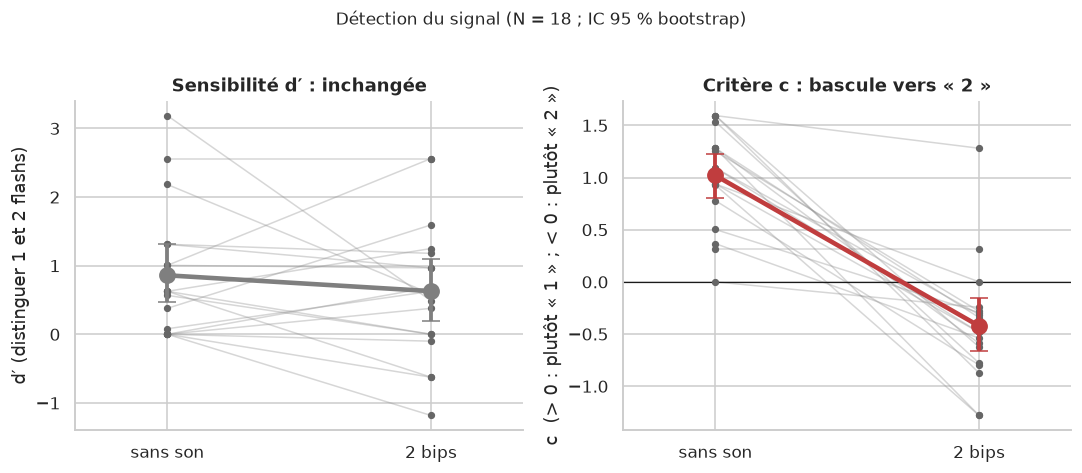

In [12]:
# Figure 4 : détection du signal
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
slope_panel(axes[0], sd["d′ sans son"], sd["d′ 2 bips"], ["sans son", "2 bips"], COL["neutre"],
            "Sensibilité d′ : inchangée", "d′ (distinguer 1 et 2 flashs)", pct=False)
slope_panel(axes[1], sd["c sans son"], sd["c 2 bips"], ["sans son", "2 bips"], COL["illusion"],
            "Critère c : bascule vers « 2 »", "c  (> 0 : plutôt « 1 » ; < 0 : plutôt « 2 »)", pct=False)
axes[1].axhline(0, color="k", lw=0.8)
fig.suptitle(f"Détection du signal (N = {N} ; IC 95 % bootstrap)", y=1.02, fontsize=11)
plt.tight_layout(); save(fig, "fig04_detection_signal")

> **Figure 4. À retenir :** les bips ne rendent pas la vision plus fine (d′ = 0,86 sans son, 0,63 avec 2 bips, p = 0,36), mais ils font basculer presque tout le monde vers la réponse « 2 » (c = 1,02 → −0,42, p < 0,001, d = 1,86). Attention : ce modèle ne permet pas à lui seul de dire si ce déplacement se fait dans la perception ou dans la décision.

## 5. Analyses exploratoires : au-delà des articles

Ces analyses n'étaient pas prévues à l'avance. Avec 18 participants, ce sont des **pistes**, sans correction pour les comparaisons multiples (sauf mention).

### 5.1 Le son aide aussi à voir un vrai double flash, et c'est lui qui « gagne »

In [13]:
display(fmt(pd.DataFrame([compare(P["2F2B"], P["2F0B"], "2 vrais flashs : avec 2 bips vs sans son", "two-sided")])))
conflict = d[d.condition.isin(["1F2B", "2F1B"])].copy()
conflict["suit_son"] = (conflict.response == conflict.n_beeps).astype(int)
suit = conflict.groupby("participant").suit_son.mean()
lo, hi = boot_ci(suit)
print(f"Essais en conflit (1F2B et 2F1B) : la réponse suit le nombre de BIPS dans "
      f"{suit.mean():.0%} des cas en moyenne (IC95 bootstrap {lo:.0%}–{hi:.0%}) ; "
      f"{(suit > 0.5).sum()} participants sur {N} suivent le son plus d'une fois sur deux.")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
2 vrais flashs : avec 2 bips vs sans son,0.5,0.33,0.65,6.0,17,"< 0,001","< 0,001",1.41


Essais en conflit (1F2B et 2F1B) : la réponse suit le nombre de BIPS dans 71% des cas en moyenne (IC95 bootstrap 61%–80%) ; 17 participants sur 18 suivent le son plus d'une fois sur deux.


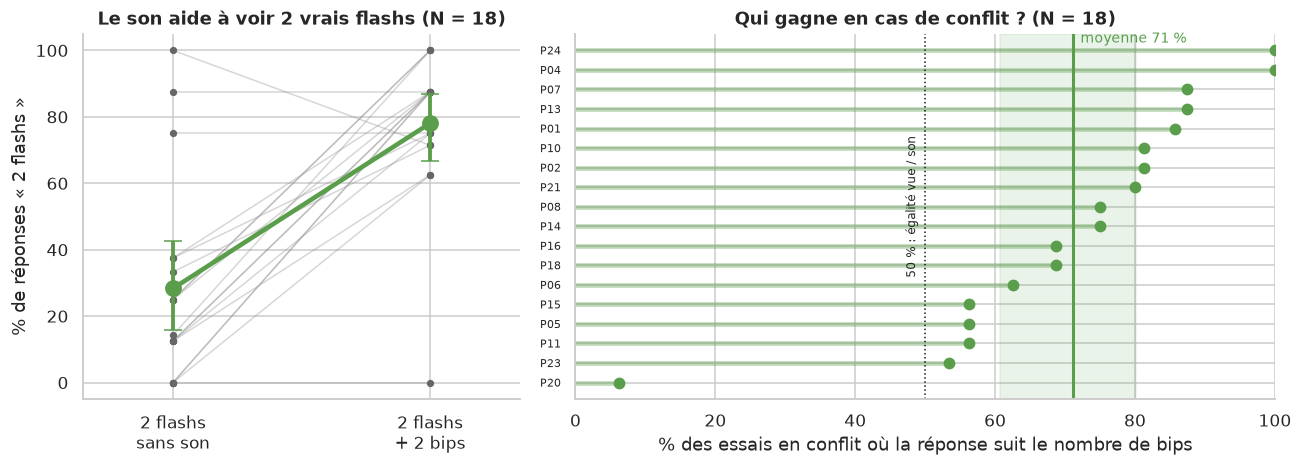

In [14]:
# Figure 5 : le son aide à voir le vrai double flash, et gagne les conflits
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
slope_panel(axes[0], P["2F0B"], P["2F2B"], ["2 flashs\nsans son", "2 flashs\n+ 2 bips"], COL["son"],
            f"Le son aide à voir 2 vrais flashs (N = {N})", "% de réponses « 2 flashs »")
axes[0].set_ylim(-5, 105)
ax = axes[1]
s = suit.sort_values() * 100
ax.hlines(range(N), 0, s.values, color=COL["son"], alpha=0.4, lw=3)
ax.scatter(s.values, range(N), color=COL["son"], s=45, zorder=3)
ax.axvline(50, color="k", ls=":", lw=1); ax.text(49, N / 2, "50 % : égalité vue / son", fontsize=8, rotation=90, ha="right", va="center")
m, lo_, hi_ = mean_ci(s)
ax.axvspan(m - lo_, m + hi_, color=COL["son"], alpha=0.12)
ax.axvline(m, color=COL["son"], lw=2); ax.text(m + 1, N - 0.6, f"moyenne {m:.0f} %", color=COL["son"], fontsize=9)
ax.set_yticks(range(N)); ax.set_yticklabels(s.index, fontsize=7)
ax.set_xlim(0, 100); ax.set_xlabel("% des essais en conflit où la réponse suit le nombre de bips")
ax.set_title(f"Qui gagne en cas de conflit ? (N = {N})")
plt.tight_layout(); save(fig, "fig05_dominance_son")

> **Figure 5. À retenir :** sans son, 2 vrais flashs ne sont vus comme 2 que dans 28 % des essais ; avec 2 bips, dans 78 % (**+50 points**, IC 95 % : 33 à 65, p < 0,001) : l'oreille corrige une vue trop lente. Et quand l'image et le son se contredisent (1F2B, 2F1B), la réponse suit **le nombre de bips dans 71 % des cas** (IC 95 % : 61 à 80 %), chez 17 participants sur 18. Pour compter des événements rapides, le cerveau se fie surtout à l'audition, plus précise dans le temps que la vision.

### 5.2 Tout le monde n'est pas trompé de la même façon

In [15]:
fis = idx.fission
print(f"Indice de fission : médiane {fis.median():.2f}, min {fis.min():.2f}, max {fis.max():.2f}")
print(f"Participants qui ont vu 2 flashs sur au moins la moitié des essais 1 flash + 2 bips : "
      f"{(P['1F2B'] >= 0.5).sum()} / {N}")
print(f"Participants qui n'ont presque jamais été trompés (≤ 1 essai sur 8) : {(P['1F2B'] <= 1/8).sum()} / {N}")
r1 = stats.spearmanr(idx.fission, idx.fusion)
r2 = stats.spearmanr(P["2F0B"], idx.fission)
print(f"\nCorrélation (Spearman) fission / fusion : rho = {r1.statistic:.2f}, p = {r1.pvalue:.3f}")
print(f"Corrélation (Spearman) bonne vision des 2 flashs sans son (2F0B) / fission : "
      f"rho = {r2.statistic:.2f}, p = {r2.pvalue:.3f}")

Indice de fission : médiane 0.50, min 0.00, max 1.00
Participants qui ont vu 2 flashs sur au moins la moitié des essais 1 flash + 2 bips : 13 / 18
Participants qui n'ont presque jamais été trompés (≤ 1 essai sur 8) : 3 / 18

Corrélation (Spearman) fission / fusion : rho = -0.15, p = 0.546
Corrélation (Spearman) bonne vision des 2 flashs sans son (2F0B) / fission : rho = -0.47, p = 0.048


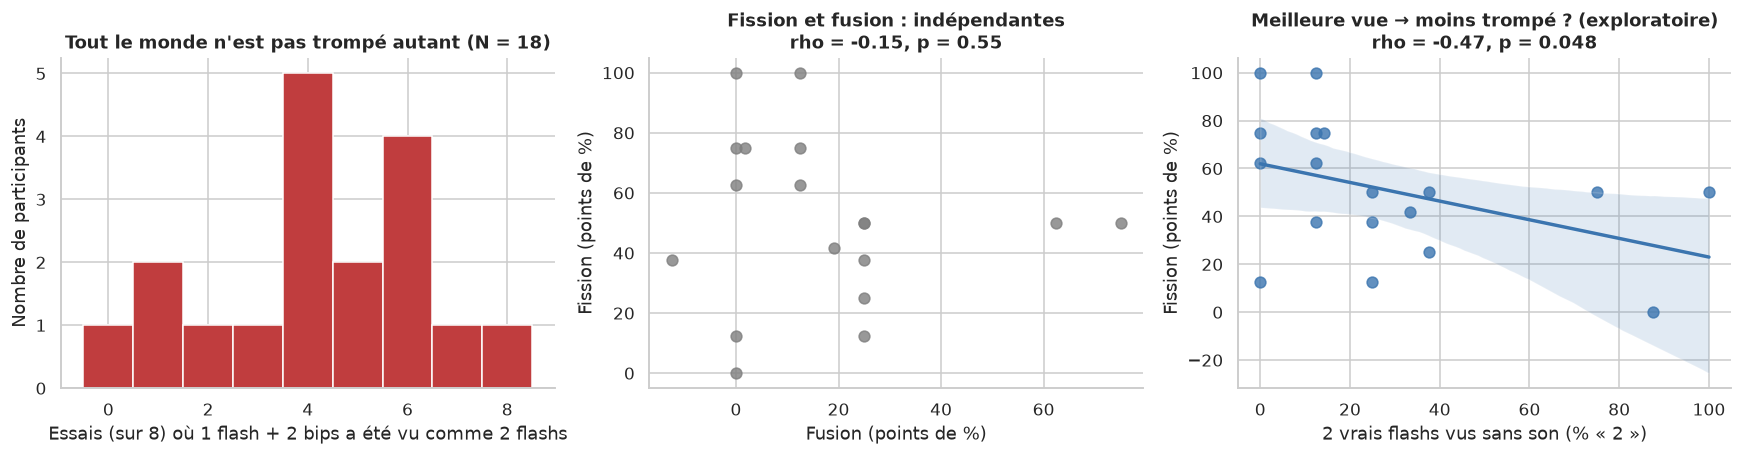

In [16]:
# Figure 6 : différences individuelles
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
n_illus = d[d.condition == "1F2B"].groupby("participant").two.sum()
axes[0].hist(n_illus, bins=np.arange(-0.5, 9.5, 1), color=COL["illusion"], edgecolor="w")
axes[0].set_xlabel("Essais (sur 8) où 1 flash + 2 bips a été vu comme 2 flashs")
axes[0].set_ylabel("Nombre de participants"); axes[0].set_title(f"Tout le monde n'est pas trompé autant (N = {N})")

axes[1].scatter(idx.fusion * 100, idx.fission * 100, s=50, color=COL["neutre"], alpha=0.8)
axes[1].set_xlabel("Fusion (points de %)"); axes[1].set_ylabel("Fission (points de %)")
axes[1].set_title(f"Fission et fusion : indépendantes\nrho = {r1.statistic:.2f}, p = {r1.pvalue:.2f}")

sns.regplot(x=P["2F0B"] * 100, y=idx.fission * 100, ax=axes[2], color=COL["1F"], ci=95,
            scatter_kws=dict(s=50, alpha=0.8), n_boot=2000, seed=2026)
axes[2].set_xlabel("2 vrais flashs vus sans son (% « 2 »)"); axes[2].set_ylabel("Fission (points de %)")
axes[2].set_title(f"Meilleure vue → moins trompé ? (exploratoire)\nrho = {r2.statistic:.2f}, p = {r2.pvalue:.3f}")
plt.tight_layout(); save(fig, "fig06_differences_individuelles")

> **Figure 6. À retenir :** l'illusion varie beaucoup d'une personne à l'autre : 13 participants sur 18 voient 2 flashs au moins une fois sur deux, mais 3 ne sont presque jamais trompés (au plus 1 essai sur 8). Être sensible à la fission ne prédit pas la sensibilité à la fusion (rho = −0,15, p = 0,55). En revanche, ceux qui voient le mieux 2 flashs sans son semblent **moins trompés** (rho = −0,47, p = 0,048 ; la zone bleue est l'IC 95 % de la droite). C'est ce que prédit l'idée que le cerveau donne plus de poids au sens le plus fiable, mais avec 18 personnes et un p tout juste sous 0,05, ce résultat est à confirmer.

### 5.3 Temps de réponse

Le temps de réponse n'était pas limité, et les consignes ne demandaient pas d'aller vite : ces résultats sont donc indicatifs. Pour chaque participant, on prend le temps **médian** (peu sensible aux réponses très lentes).

In [17]:
med = lambda cond, resp: d[(d.condition == cond) & (d.response == resp)].groupby("participant").rt_ms.median()
rt_illus, rt_vrai, rt_non = med("1F2B", 2), med("2F2B", 2), med("1F2B", 1)
both = rt_illus.index.intersection(rt_vrai.index)
both2 = rt_illus.index.intersection(rt_non.index)
display(fmt(pd.DataFrame([
    compare(rt_illus[both], rt_vrai[both], "TR (ms) : « 2 » illusoire (1F2B) vs « 2 » juste (2F2B)", "two-sided"),
    compare(rt_illus[both2], rt_non[both2], "TR (ms) : 1F2B répondu « 2 » vs répondu « 1 »", "two-sided")])))
print(f"n = {len(both)} et {len(both2)} participants. Médianes du groupe : illusoire {rt_illus.median():.0f} ms, "
      f"2 vrais flashs {rt_vrai.median():.0f} ms, 1F2B répondu « 1 » {rt_non.median():.0f} ms")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
TR (ms) : « 2 » illusoire (1F2B) vs « 2 » juste (2F2B),272.56,114.45,449.57,3.03,15,0.008,0.005,0.76
TR (ms) : 1F2B répondu « 2 » vs répondu « 1 »,151.62,-271.89,572.51,0.69,14,0.501,0.359,0.18


n = 16 et 15 participants. Médianes du groupe : illusoire 771 ms, 2 vrais flashs 601 ms, 1F2B répondu « 1 » 738 ms


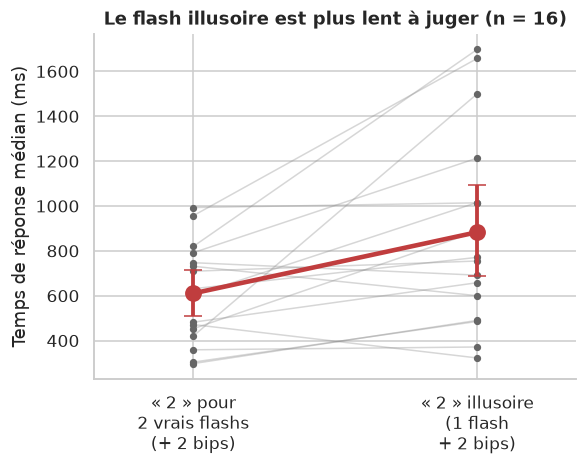

In [18]:
# Figure 7 : temps de réponse
fig, ax = plt.subplots(figsize=(5.5, 4.4))
slope_panel(ax, rt_vrai[both], rt_illus[both], ["« 2 » pour\n2 vrais flashs\n(+ 2 bips)", "« 2 » illusoire\n(1 flash\n+ 2 bips)"],
            COL["illusion"], f"Le flash illusoire est plus lent à juger (n = {len(both)})",
            "Temps de réponse médian (ms)", pct=False)
plt.tight_layout(); save(fig, "fig07_temps_reponse")

> **Figure 7. À retenir :** répondre « 2 » pour 1 flash + 2 bips (réponse illusoire) prend **≈ 270 ms de plus** que répondre « 2 » pour 2 vrais flashs avec 2 bips (IC 95 % : 114 à 450 ms, p = 0,008, n = 16 participants ayant les deux types de réponse). Cela suggère que le flash illusoire est moins net qu'un vrai. Dans la condition 1F2B, les réponses « 2 » ne sont pas plus lentes que les réponses « 1 » (p = 0,50, n = 15).

### 5.4 Tendance au cours de la session

On découpe les 58 essais en 4 blocs successifs (la pause tombe entre les blocs 2 et 3). Pour chaque participant, on calcule la **pente** de chaque mesure d'un bloc à l'autre (en points de % par bloc), puis on teste si la pente moyenne diffère de 0. Chaque condition n'a qu'environ 2 essais par bloc et par personne : les points individuels sont très bruités, seule la moyenne du groupe est interprétable.

In [19]:
# Évolution au cours de la session : 4 blocs successifs de ~14-15 essais
N_BLOCS = 4
d["bloc"] = np.ceil(d.trial_in_block / (n_expected / N_BLOCS)).astype(int).clip(1, N_BLOCS)
mesures = {"fission : 1 flash + 2 bips vu « 2 »": ("1F2B", 1),
           "fusion : 2 flashs + 1 bip vu « 1 »": ("2F1B", 0),
           "2 vrais flashs + 2 bips vu « 2 »": ("2F2B", 1),
           "contrôle : 1 flash seul vu « 2 »": ("1F0B", 1)}
traj = {}
for lab, (cond, want_two) in mesures.items():
    sub = d[d.condition == cond]
    v = sub.groupby(["participant", "bloc"]).two.mean().unstack()
    traj[lab] = v if want_two else 1 - v
# tendance : pente individuelle (points de % par bloc), puis test de la pente moyenne contre 0
pentes = {}
for lab, v in traj.items():
    sl = v.apply(lambda r: np.polyfit(r.dropna().index, r.dropna().values * 100, 1)[0]
                 if r.notna().sum() >= 3 else np.nan, axis=1).dropna()
    lo, hi = boot_ci(sl)
    pentes[lab] = pd.Series({"pente moyenne (pts / bloc)": sl.mean(), "IC95 bas": lo, "IC95 haut": hi,
                             "p (t)": stats.ttest_1samp(sl, 0).pvalue, "p (Wilcoxon)": stats.wilcoxon(sl).pvalue,
                             "n": len(sl)})
pentes = pd.DataFrame(pentes).T
display(pentes.assign(**{c: pentes[c].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
                         for c in ["p (t)", "p (Wilcoxon)"]}).round(2))
print(f"1F2B, première moitié vs deuxième : "
      f"{100*d[(d.condition=='1F2B') & (d.bloc<=2)].groupby('participant').two.mean().mean():.0f} % -> "
      f"{100*d[(d.condition=='1F2B') & (d.bloc>2)].groupby('participant').two.mean().mean():.0f} %")

,pente moyenne (pts / bloc),IC95 bas,IC95 haut,p (t),p (Wilcoxon),n
fission : 1 flash + 2 bips vu « 2 »,-5.35,-14.35,3.57,0.275,0.287,18.0
fusion : 2 flashs + 1 bip vu « 1 »,1.06,-3.55,6.28,0.683,0.583,17.0
2 vrais flashs + 2 bips vu « 2 »,-10.32,-16.88,-4.34,0.006,0.004,18.0
contrôle : 1 flash seul vu « 2 »,0.18,-2.80,3.75,0.918,1.000,18.0


1F2B, première moitié vs deuxième : 62 % -> 45 %


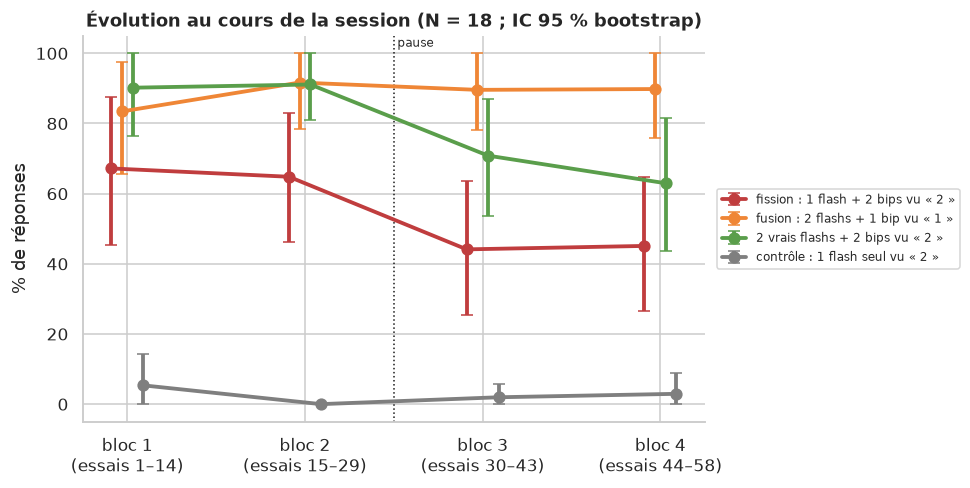

In [20]:
# Figure 8 : la tendance au cours de la session
fig, ax = plt.subplots(figsize=(9, 4.6))
couleurs = [COL["illusion"], COL["2F"], COL["son"], COL["neutre"]]
for (lab, v), c, dx in zip(traj.items(), couleurs, [-0.09, -0.03, 0.03, 0.09]):
    stat = [mean_ci(v[b] * 100) for b in v.columns]
    ax.errorbar(v.columns + dx, [s[0] for s in stat], yerr=[[s[1] for s in stat], [s[2] for s in stat]],
                fmt="o-", color=c, lw=2.5, ms=7, capsize=4, label=lab)
ax.axvline(2.5, color="k", ls=":", lw=1); ax.text(2.52, 101, "pause", fontsize=8, va="bottom")
ax.set_xticks(range(1, N_BLOCS + 1)); ax.set_xticklabels([f"bloc {b}\n(essais {int((b-1)*n_expected/N_BLOCS)+1}–{int(b*n_expected/N_BLOCS)})" for b in range(1, N_BLOCS + 1)])
ax.set_ylim(-5, 105); ax.set_ylabel("% de réponses")
ax.set_title(f"Évolution au cours de la session (N = {N} ; IC 95 % bootstrap)")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); save(fig, "fig08_evolution_session")

> **Figure 8. À retenir :** les réponses au flash seul (contrôle) et la fusion restent stables. **L'aide du son pour voir 2 vrais flashs s'use** : 2F2B vu « 2 » passe d'environ 90 % au début à environ 63 % à la fin (pente −10 points par bloc, IC 95 % : −17 à −4, p = 0,006 ; encore significatif après correction de Bonferroni pour les 4 tests). La fission baisse aussi (62 % dans la 1re moitié, 45 % dans la 2e ; pente −5 points par bloc), mais cette baisse **n'est pas significative** (p = 0,28). Une explication possible : avec l'habitude, les participants s'appuient un peu moins sur le son. Cela reste à confirmer.

### 5.5 Type de son et âge

Groupes très petits (4 casques filaires contre 14 haut-parleurs ; 8 personnes de 18–21 ans contre 10 de 22–25 ans) : simple description, test de Mann-Whitney.

In [21]:
info = q.loc[kept, ["son", "age"]].join(idx)
for col in ["son", "age"]:
    print(info.groupby(col)[["fission", "fusion", "fission_200ms"]].agg(["mean", "count"]).round(2), "\n")
    grp = [gp.fission.values for _, gp in info.groupby(col)]
    u = stats.mannwhitneyu(*grp, alternative="two-sided")
    print(f"Mann-Whitney sur la fission ({col}) : U = {u.statistic:.1f}, p = {u.pvalue:.3f}\n")

         fission       fusion       fission_200ms      
            mean count   mean count          mean count
son                                                    
speakers    0.53    14   0.18    14          0.08    14
wired       0.45     4   0.14     4          0.12     4 

Mann-Whitney sur la fission (son) : U = 34.5, p = 0.520

      fission       fusion       fission_200ms      
         mean count   mean count          mean count
age                                                 
18-21    0.61     8   0.23     8          0.13     8
22-25    0.43    10   0.12    10          0.05    10 

Mann-Whitney sur la fission (age) : U = 55.5, p = 0.179



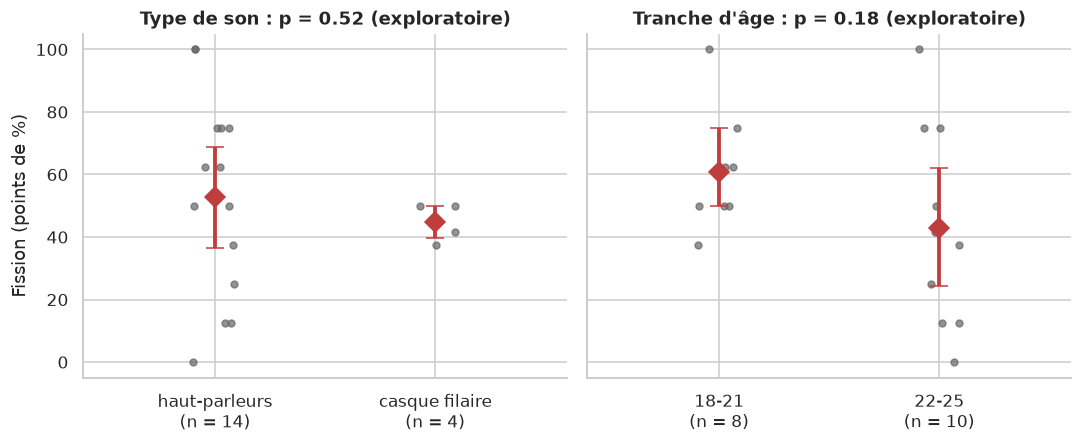

In [22]:
# Figure 9 : type de son et âge (exploratoire, petits groupes)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
lab = {"speakers": "haut-parleurs", "wired": "casque filaire"}
for ax, col, titre in [(axes[0], "son", "Type de son"), (axes[1], "age", "Tranche d'âge")]:
    levels = sorted(info[col].unique())
    for i, lev in enumerate(levels):
        v = info.loc[info[col] == lev, "fission"] * 100
        x = i + np.random.default_rng(i).uniform(-0.1, 0.1, len(v))
        ax.scatter(x, v, color="0.4", s=20, alpha=0.7)
        m, lo, hi = mean_ci(v)
        ax.errorbar(i, m, yerr=[[lo], [hi]], fmt="D", color=COL["illusion"], ms=9, capsize=6, lw=2.5)
    p = stats.mannwhitneyu(*[info.loc[info[col] == l, "fission"] for l in levels]).pvalue
    ax.set_xticks(range(len(levels))); ax.set_xlim(-0.6, len(levels) - 0.4)
    ax.set_xticklabels([f"{lab.get(l, l)}\n(n = {(info[col] == l).sum()})" for l in levels])
    ax.set_title(f"{titre} : p = {p:.2f} (exploratoire)")
axes[0].set_ylabel("Fission (points de %)")
plt.tight_layout(); save(fig, "fig09_son_age")

> **Figure 9. À retenir :** aucune différence nette. La fission vaut 45 points en casque filaire contre 53 sur haut-parleurs (p = 0,52), et 61 points chez les 18–21 ans contre 43 chez les 22–25 ans (p = 0,18). Avec si peu de personnes par groupe, l'absence de différence ne prouve pas qu'il n'y en a pas. Le résultat rassure quand même : les haut-parleurs n'ont pas détruit l'illusion.

## 6. Robustesse : sans aucune exclusion de session

In [23]:
dall = main[~main.exclude_trial]
Pa = dall.pivot_table(index="participant", columns="condition", values="two", aggfunc="mean")
display(fmt(pd.DataFrame([
    compare(Pa["1F2B"], Pa["1F0B"], "H1 fission"),
    compare(1 - Pa["2F1B"], 1 - Pa["2F0B"], "H2 fusion"),
    compare(Pa["1F2B"] - Pa["1F0B"], Pa["2F0B"] - Pa["2F1B"], "H3 fission > fusion"),
    compare(Pa["1F2B"], Pa["1F2B_gap200"], "H5 57 vs 200 ms")])))
print(f"N = {len(Pa)} sessions")

,différence moyenne,IC95 bas,IC95 haut,t,ddl,p (t),p (Wilcoxon),d de Cohen (dz)
H1 fission,0.51,0.40,0.63,8.50,23,"< 0,001","< 0,001",1.74
H2 fusion,0.12,-0.01,0.24,1.94,23,0.032,0.003,0.40
H3 fission > fusion,0.39,0.21,0.58,4.08,23,"< 0,001","< 0,001",0.83
H5 57 vs 200 ms,0.46,0.32,0.59,6.43,23,"< 0,001","< 0,001",1.31


N = 24 sessions


Avec les 24 sessions, H1, H3 et H5 restent nettes (p < 0,001). La fusion (H2) est plus faible (+12 points, t(23) = 1,94, p = 0,03 ; Wilcoxon p = 0,003 ; l'IC 95 %, de −1 à +24 points, inclut tout juste 0). Les sessions exclues (écrans à 30 Hz notamment) affichaient probablement mal le double flash, ce qui brouille surtout cette illusion, la plus fragile. Les conclusions ne dépendent donc pas des exclusions.

## 7. Qualité du timing (mesurée par le navigateur)

In [24]:
tim = main[main.participant.isin(kept)]
print(f"Écran : {tim.refresh_hz.median():.1f} Hz en médiane ; durée réelle d'un flash : "
      f"{tim.flash_dur_ms_actual.median():.1f} ms ; écart réel entre 2 flashs : {tim[tim.part=='core'].flash_soa_ms_actual.median():.1f} ms")
print(f"Images perdues : {(tim.n_dropped_frames > 0).mean():.1%} des essais ; "
      f"décalage son-image estimé par le navigateur : médiane {tim.av_offset_est_ms.abs().median():.2f} ms, "
      f"max {tim.av_offset_est_ms.abs().max():.1f} ms")
print(f"Latence de sortie audio annoncée : médiane {tim.output_latency_ms.median():.0f} ms "
      f"(prise en compte par le programme via getOutputTimestamp)")

Écran : 60.0 Hz en médiane ; durée réelle d'un flash : 16.7 ms ; écart réel entre 2 flashs : 50.0 ms
Images perdues : 1.5% des essais ; décalage son-image estimé par le navigateur : médiane 0.40 ms, max 6.0 ms
Latence de sortie audio annoncée : médiane 39 ms (prise en compte par le programme via getOutputTimestamp)


Le navigateur ne peut mesurer ni l'instant où la lumière sort de l'écran, ni celui où le son sort du casque. Mais ce qu'il peut mesurer est bon : flash d'une image à 60 Hz (16,7 ms), écart de 50 ms respecté, peu d'images perdues, son programmé au bon moment.

## 8. Conclusion

Avec **18 participants** testés en ligne sur leur propre ordinateur, on retrouve l'illusion de Shams et al. (2000) avec un effet très fort : **un flash accompagné de deux bips est vu comme deux flashs dans plus de la moitié des essais**. On retrouve aussi l'illusion inverse (fusion), plus faible, et on montre que tout dépend du **timing** : à 200 ms d'écart entre les bips, l'illusion disparaît presque.

Ce que ces données ajoutent : le son ne fait pas que tromper, il **aide aussi** à voir un vrai double flash trop rapide pour l'œil ; il « gagne » dans 71 % des conflits ; les personnes qui voient bien sans son semblent moins trompées ; et l'aide apportée par le son s'use au fil de la session. Tout cela va dans le même sens : **pour compter des événements rapides, le cerveau fait surtout confiance au sens le plus précis dans le temps, l'audition.**

## 9. Limites

- **Échantillon** petit et de convenance : 18 personnes de 18 à 25 ans.
- **Peu d'essais par condition** (6 à 8, environ 2 par bloc en section 5.4), donc des scores individuels bruités.
- **Matériel** : son et image non mesurés physiquement ; matériel différent d'une personne à l'autre ; surtout des haut-parleurs.
- **Réponses** limitées à 1 ou 2 flashs (Shams et al. allaient jusqu'à 4).
- **Anonymat** : une même personne a pu faire l'expérience deux fois.
- **Analyses exploratoires** (section 5) : elles n'étaient pas prévues et demandent à être confirmées sur un autre groupe.

**Références.** Shams, Kamitani & Shimojo (2000), *Nature* 408:788 · Shams, Kamitani & Shimojo (2002), *Cognitive Brain Research* 14:147 · Andersen, Tiippana & Sams (2004), *Cognitive Brain Research* 21:301 · Hautus (1995), *Behavior Research Methods* 27:46.